# 1.3 Mengimport Data yang dibutuhkan ke dalam Neo4J

In [1]:
import argparse
import os
import sys
from neo4j import GraphDatabase
import pandas as pd
from tqdm import tqdm

In [ ]:
# membuat driver & session
uri = "bolt://127.0.0.1:7687"
user = "neo4j"
password = "Audy77Alycia"  # Password Neo4j

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="neo4j")

In [3]:
# Fungsi parse_arguments()
def parse_arguments():
  parser = argparse.ArgumentParser(
      description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
  )
  parser.add_argument(
      "-u",
      "--user",
      default="neo4j",
      help="Username Neo4j (default: neo4j)",
  )
  parser.add_argument(
      "-p",
      "--password",
      default="Audy77Alycia", 
      help="Password Neo4J (default: neo4j)",
  )
  parser.add_argument(
      "-b",
      "--bolt",
      default="bolt://127.0.0.1:7687",  # Pakai bolt:// agar kompatibel dengan local instance
      help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
  )
  parser.add_argument(
      "-s",
      "--source",
      default=".",  
      help="Direktori/folder sumber data (default: data)",
  )
  # Tambahkan args=[] agar argparse tidak error membaca argumen kernel Jupyter
  return parser.parse_args(args=[])

In [4]:
# Fungsi Helper Constraint
def create_constraints(session):
  session.run(
      "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS FOR (v:Visitor)"
      " REQUIRE v.visitorId IS UNIQUE"
  )
  session.run(
      "CREATE CONSTRAINT item_id_unique IF NOT EXISTS FOR (i:Item) REQUIRE"
      " i.itemId IS UNIQUE"
  )

In [ ]:
# Fungsi Import Batch
def import_batch(tx, batch):
  cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
  tx.run(cypher_query, batch=batch)

In [6]:
args = parse_arguments()

In [7]:
# Mencari dulu di folder acuan default 
csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
  csv_file_path = os.path.join("ecommerce-dataset", "events.csv")

if not os.path.exists(csv_file_path):
  print(
      "Error: File 'events.csv' tidak ditemukan di folder utama maupun"
      " ecommerce-dataset!"
  )
  sys.exit(1)

print(f"File berhasil ditemukan di: {csv_file_path}")

File berhasil ditemukan di: ecommerce-dataset\events.csv


In [8]:
# Pembuatan koneksi
try:
  driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
  driver.verify_connectivity()
  print("Koneksi berhasil terverifikasi.")
except Exception as e:
  print(f"Gagal terhubung ke database: {e}")
  sys.exit(1)

Koneksi berhasil terverifikasi.


In [9]:
# Proses impor dengan mekanisme batch
batch_size = 10000

with driver.session(database="neo4j") as session:
  create_constraints(session)

  print(f"Membaca file data dari: {csv_file_path}")
  chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

  total_rows = 2756101
  total_chunks = (total_rows // batch_size) + 1

  print("Memulai proses impor data ke Neo4j...")
  for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
    # Membersihkan data null/NaN pada transactionid
    chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
    records = chunk.to_dict(orient="records")
    session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: ecommerce-dataset\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [06:25<00:00,  1.40s/it]

Proses impor berhasil.


# 2.1 Wrangling dan EDA

### 1.	Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama! (akan ditentukan)
Misal: Fold training (P1) → (16-30 Juni 2015); Fold testing (P2) (16-31 Agustus 2015).

In [22]:
import os
import pandas as pd
from neo4j import GraphDatabase

In [16]:
# Tentukan lokasi folder file dataset
folder_path = "ecommerce-dataset"
file_part1 = os.path.join(folder_path, "item_properties_part1.csv")
file_part2 = os.path.join(folder_path, "item_properties_part2.csv")

In [17]:
# Baca file item_properties part 1 dan part 2
print("Membaca file item_properties...")
df_prop1 = pd.read_csv(file_part1)
df_prop2 = pd.read_csv(file_part2)

Membaca file item_properties...


In [ ]:
# Gabungkan menjadi satu DataFrame 'df_properties'
df_properties = pd.concat([df_prop1, df_prop2], ignore_index=True)

In [ ]:
# Cek tanggal paling awal dan paling akhir di dataset kamu
sample_date = pd.to_datetime(df_properties["timestamp"], unit="ms")
print("\n=== HASIL PENGECEKAN TANGGAL DATASET ===")
print("Tanggal paling awal di data :", sample_date.min())
print("Tanggal paling akhir di data:", sample_date.max())


=== HASIL PENGECEKAN TANGGAL DATASET ===
Tanggal paling awal di data : 2015-05-10 03:00:00
Tanggal paling akhir di data: 2015-09-13 03:00:00


In [20]:
# Konversi tanggal otomatis lewat Pandas (UTC)
P1_START = int(pd.Timestamp("2015-06-16 00:00:00", tz="UTC").timestamp() * 1000)
P1_END = int(
    pd.Timestamp("2015-06-30 23:59:59.999", tz="UTC").timestamp() * 1000
)

P2_START = int(pd.Timestamp("2015-08-16 00:00:00", tz="UTC").timestamp() * 1000)
P2_END = int(
    pd.Timestamp("2015-08-31 23:59:59.999", tz="UTC").timestamp() * 1000
)

print("Range P1 (ms):", P1_START, "s/d", P1_END)
print("Range P2 (ms):", P2_START, "s/d", P2_END)

Range P1 (ms): 1434412800000 s/d 1435708799999
Range P2 (ms): 1439683200000 s/d 1441065599999


In [ ]:
# Konversi Tanggal P1 dan P2 ke Timestamp (ms)
P1_START = int(pd.Timestamp("2015-06-16 00:00:00", tz="UTC").timestamp() * 1000)
P1_END = int(
    pd.Timestamp("2015-06-30 23:59:59.999", tz="UTC").timestamp() * 1000
)

P2_START = int(pd.Timestamp("2015-08-16 00:00:00", tz="UTC").timestamp() * 1000)
P2_END = int(
    pd.Timestamp("2015-08-31 23:59:59.999", tz="UTC").timestamp() * 1000
)

In [ ]:
# Buka Koneksi ke Neo4j
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)

In [25]:
def get_period_stats(session, period_name, start_ts, end_ts):
  query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE r.timestamp >= $start_ts AND r.timestamp <= $end_ts
    RETURN 
        $period AS Periode,
        type(r) AS Jenis_Interaksi,
        count(r) AS Jumlah_Relasi,
        count(DISTINCT v) AS Visitor_Unik,
        count(DISTINCT i) AS Item_Unik
    """
  result = session.run(query, start_ts=start_ts, end_ts=end_ts, period=period_name)
  return result.data()

In [ ]:
# Eksekusi Query untuk P1 dan P2
with driver.session(database="neo4j") as session:
  stats_p1 = get_period_stats(session, "P1 (Training)", P1_START, P1_END)
  stats_p2 = get_period_stats(session, "P2 (Testing)", P2_START, P2_END)

driver.close()

In [ ]:
# Gabungkan & Tampilkan Tabel Ringkasan
df_p1 = pd.DataFrame(stats_p1)
df_p2 = pd.DataFrame(stats_p2)
df_ringkasan = pd.concat([df_p1, df_p2], ignore_index=True)

print("=== HASIL FILTER & STATISTIK GRAF PERIODE P1 DAN P2 ===")
display(df_ringkasan)

=== HASIL FILTER & STATISTIK GRAF PERIODE P1 DAN P2 ===


,Periode,Jenis_Interaksi,Jumlah_Relasi,Visitor_Unik,Item_Unik
0,P1 (Training),VIEWED,299133,160882,80858
1,P1 (Training),ADDED_TO_CART,7985,4584,4971
2,P1 (Training),BOUGHT,2712,1495,2098
3,P2 (Testing),VIEWED,277534,163224,79194
4,P2 (Testing),ADDED_TO_CART,7778,4484,4750
5,P2 (Testing),BOUGHT,2541,1397,1945


Untuk filter data interaksi, periode waktunya dibagi menjadi dua bagian, yaitu P1 (Training) pada rentang 16–30 Juni 2015 dan P2 (Testing) pada 16–31 Agustus 2015. Karena di Neo4j tanggalnya disimpan dalam format Unix Timestamp (milisekon), nilai P1 diatur dari 1434412800000 sampai 1435708799999, sedangkan P2 diatur dari 1439683200000 sampai 1441065599999.

Dari hasil filter di Neo4j, periode P1 mencatat 299.133 interaksi VIEWED, 7.985 ADDED_TO_CART, dan 2.712 BOUGHT dengan total 160.882 visitor unik. Sementara untuk periode P2, tercatat 277.534 VIEWED, 7.778 ADDED_TO_CART, dan 2.541 BOUGHT dari 163.224 visitor unik. Terlihat kalau di kedua rentang waktu tersebut aktivitas pengunjung sebagian besar memang cuma melihat-lihat produk dibanding sampai transaksi pembelian.

Berikut ini diambil 20 sampel yang interaksi di periode P1.
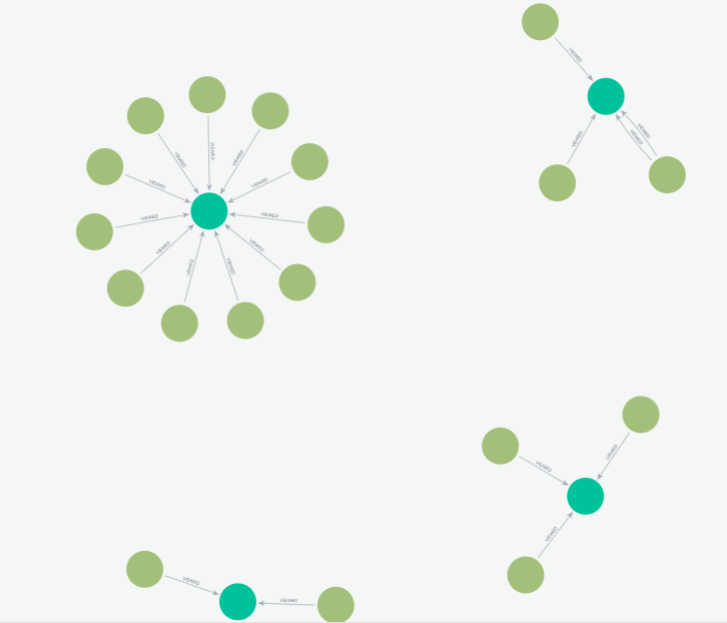

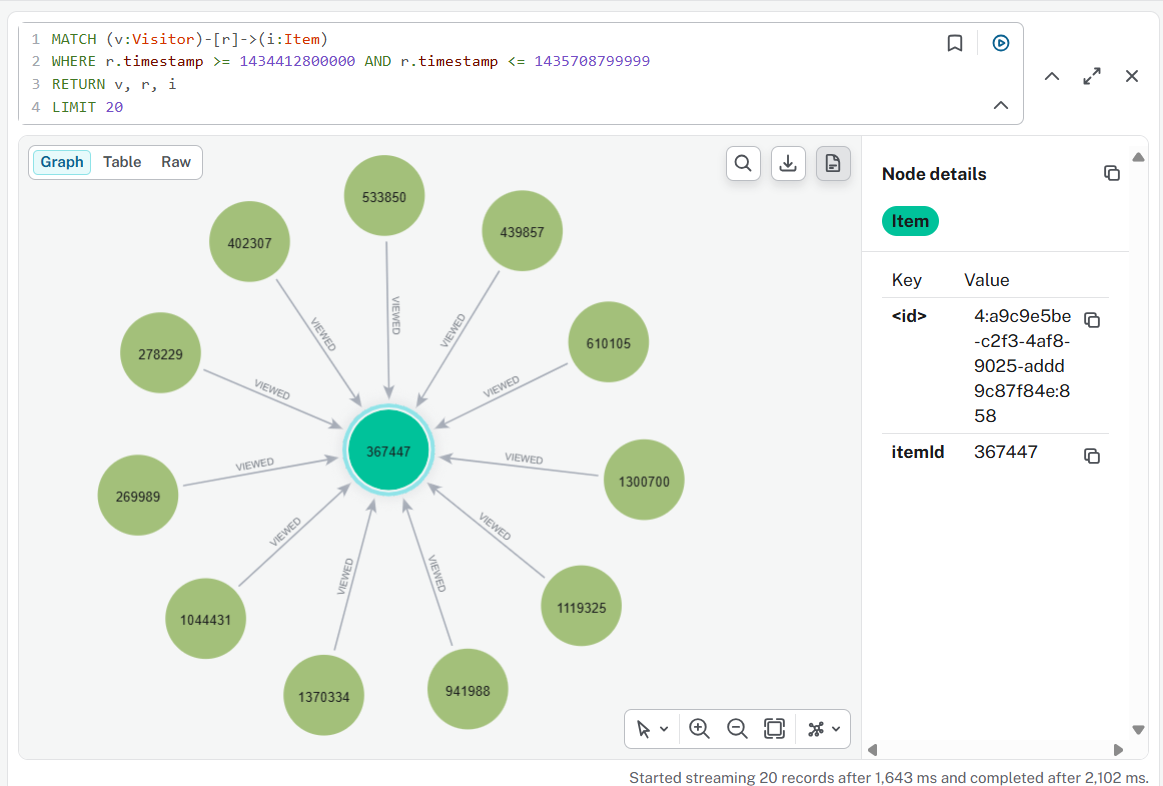

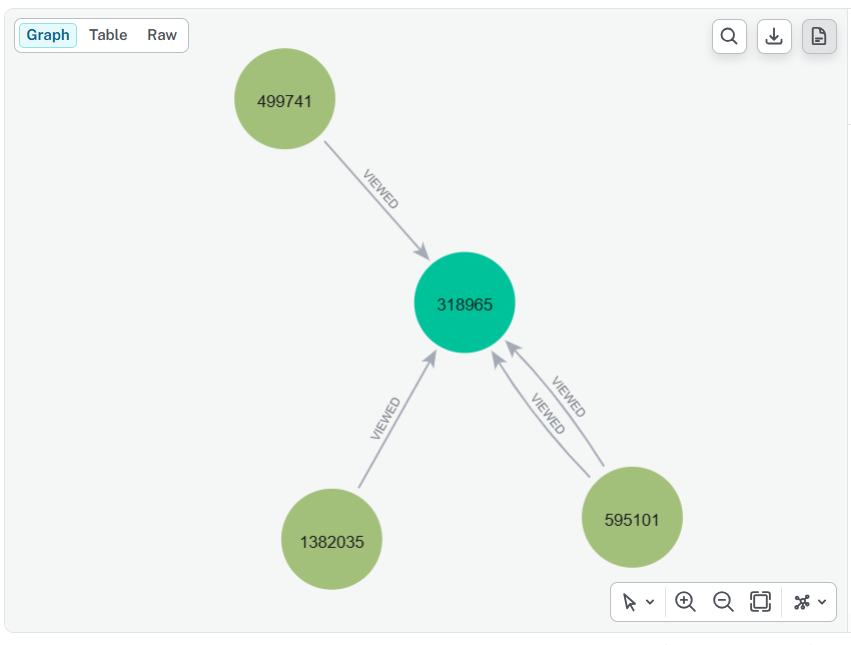

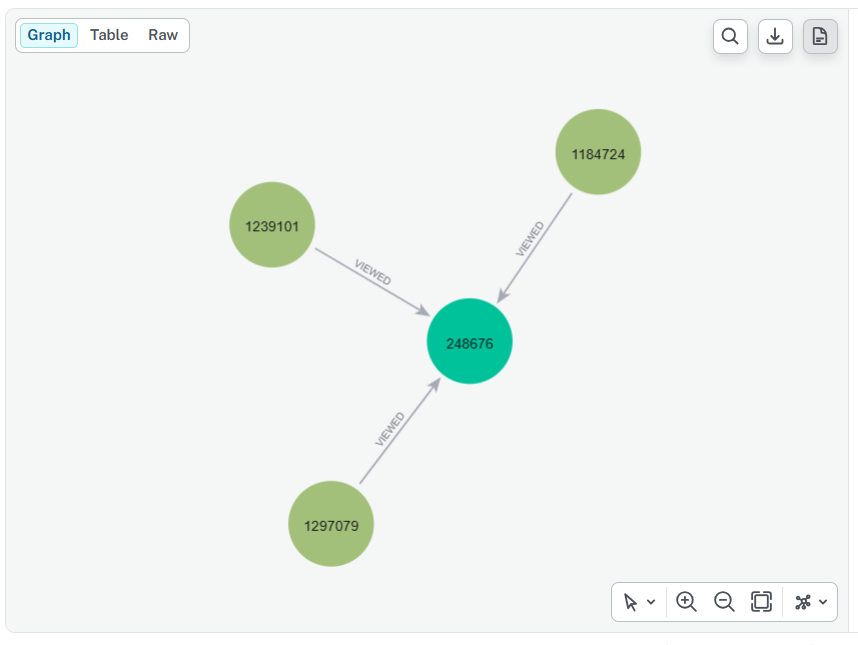

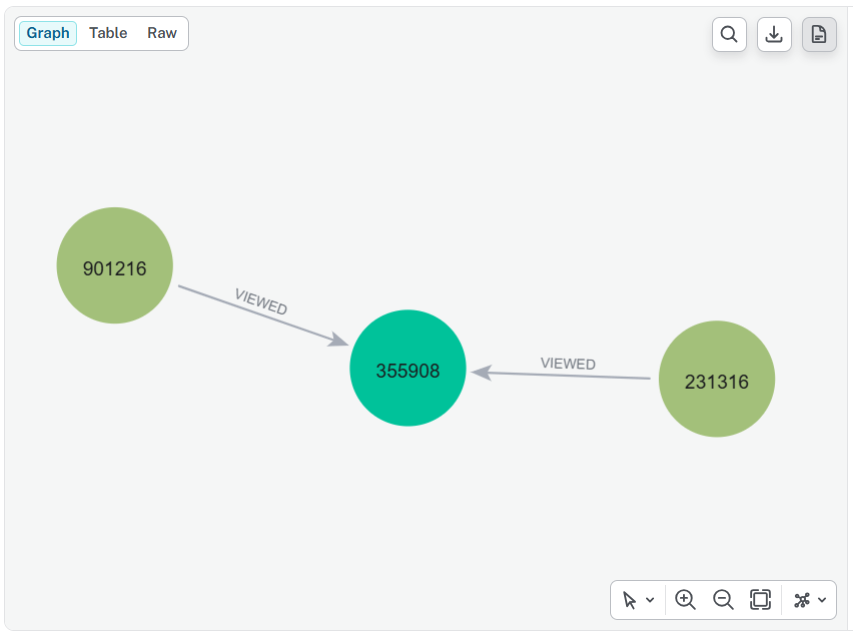

Visualisasi graf periode P1 menampilkan hubungan antara Visitor (node hijau muda) dan Item (node hijau toska). Tanda panah berlabel VIEWED menunjukkan aktivitas pengunjung yang melihat produk tersebut. Jika terdapat dua garis panah sejajar dari visitor yang sama, artinya produk tersebut dilihat beberapa kali pada waktu berbeda. Pola menyebar seperti bintang pada item tertentu (seperti 367447) menandakan produk tersebut populer dan paling banyak dikunjungi selama rentang waktu P1.




### 2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

#### Persiapan

In [45]:
import os
import pandas as pd

In [46]:
# Rentang Timestamp P1 dan P2 (ms)
P1_START = int(
    pd.Timestamp("2015-06-16 00:00:00", tz="UTC").timestamp() * 1000
)
P1_END = int(
    pd.Timestamp("2015-06-30 23:59:59.999", tz="UTC").timestamp() * 1000
)

P2_START = int(
    pd.Timestamp("2015-08-16 00:00:00", tz="UTC").timestamp() * 1000
)
P2_END = int(
    pd.Timestamp("2015-08-31 23:59:59.999", tz="UTC").timestamp() * 1000
)

In [47]:
# Baca file events.csv
file_events = os.path.join("ecommerce-dataset", "events.csv")
df_events = pd.read_csv(file_events)

In [48]:
# Filter data interaksi P1 dan P2
df_events_p1 = df_events[
    (df_events["timestamp"] >= P1_START) & (df_events["timestamp"] <= P1_END)
]
df_events_p2 = df_events[
    (df_events["timestamp"] >= P2_START) & (df_events["timestamp"] <= P2_END)
]

In [49]:
# Simpan ke file .csv
df_events_p1.to_csv("events_p1.csv", index=False)
df_events_p2.to_csv("events_p2.csv", index=False)

print("File events_p1.csv dan events_p2.csv berhasil disimpan!")

File events_p1.csv dan events_p2.csv berhasil disimpan!


Proses filter data interaksi dilakukan pada tahap persiapan data (data preparation) dengan memanfaatkan pustaka Pandas di Python. Berdasarkan batas waktu yang ditentukan, tanggal 16–30 Juni 2015 untuk periode P1 dan 16–31 Agustus 2015 untuk periode P2 dikonversi terlebih dahulu ke dalam format Unix Timestamp milisekon.
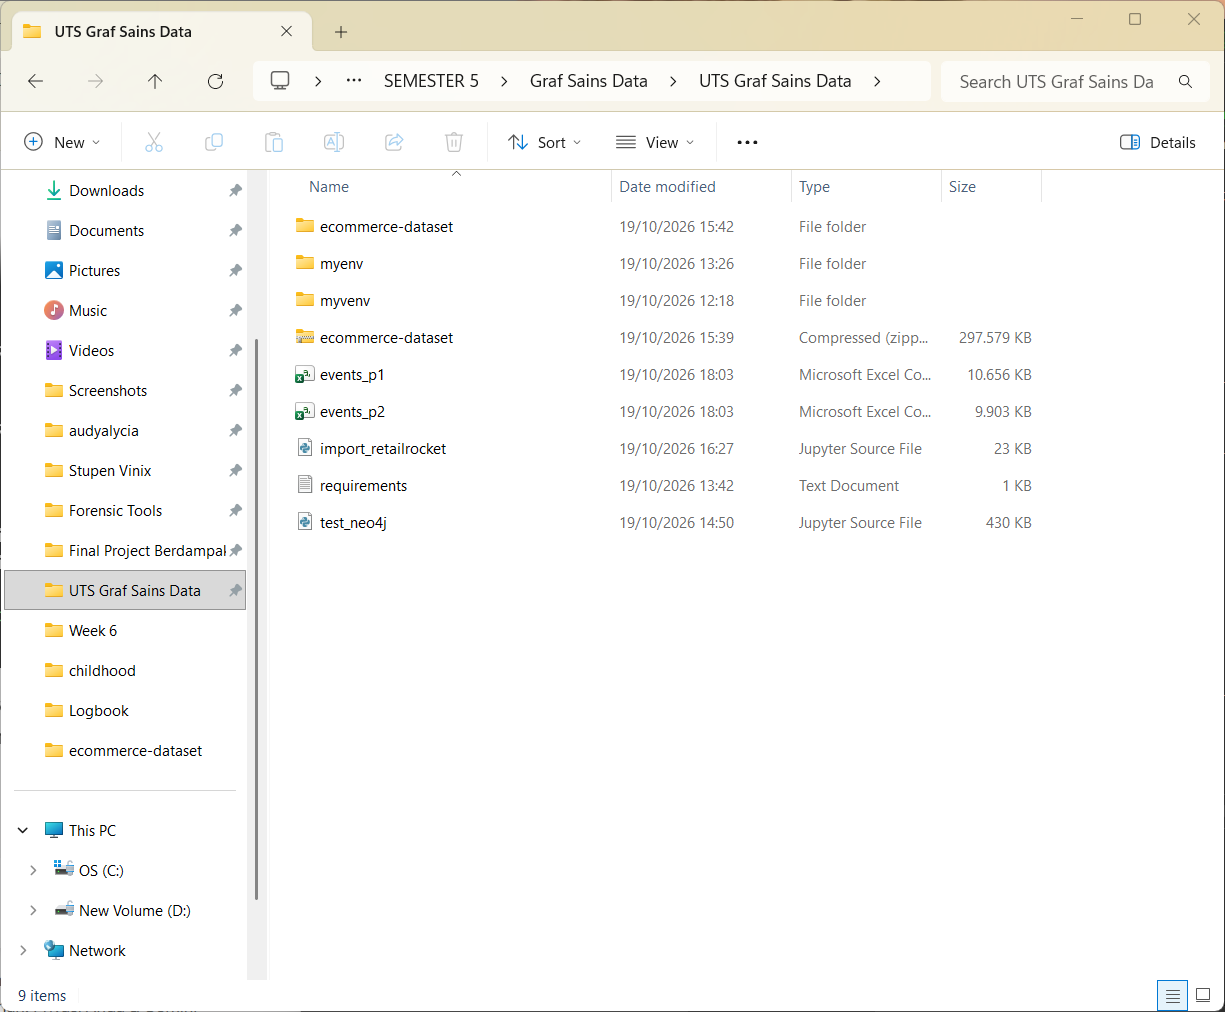
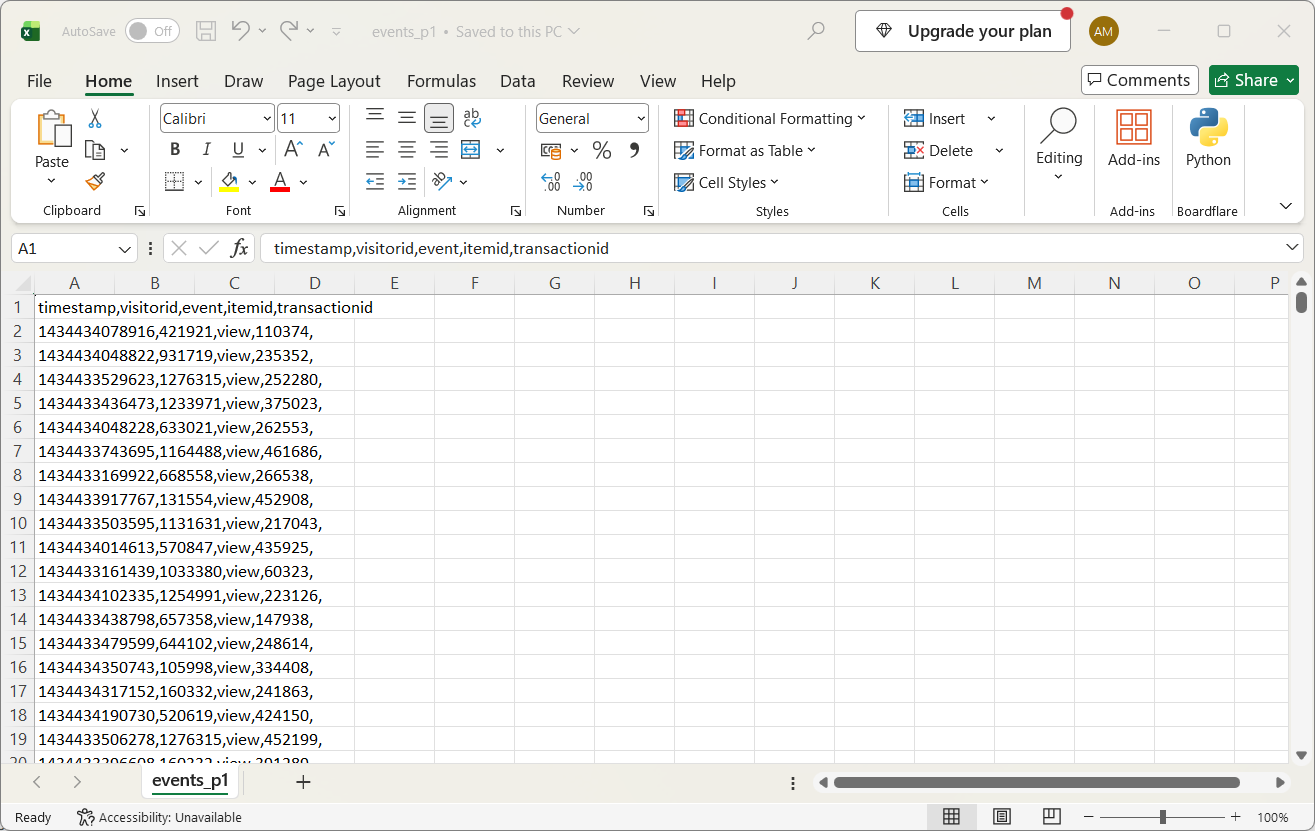
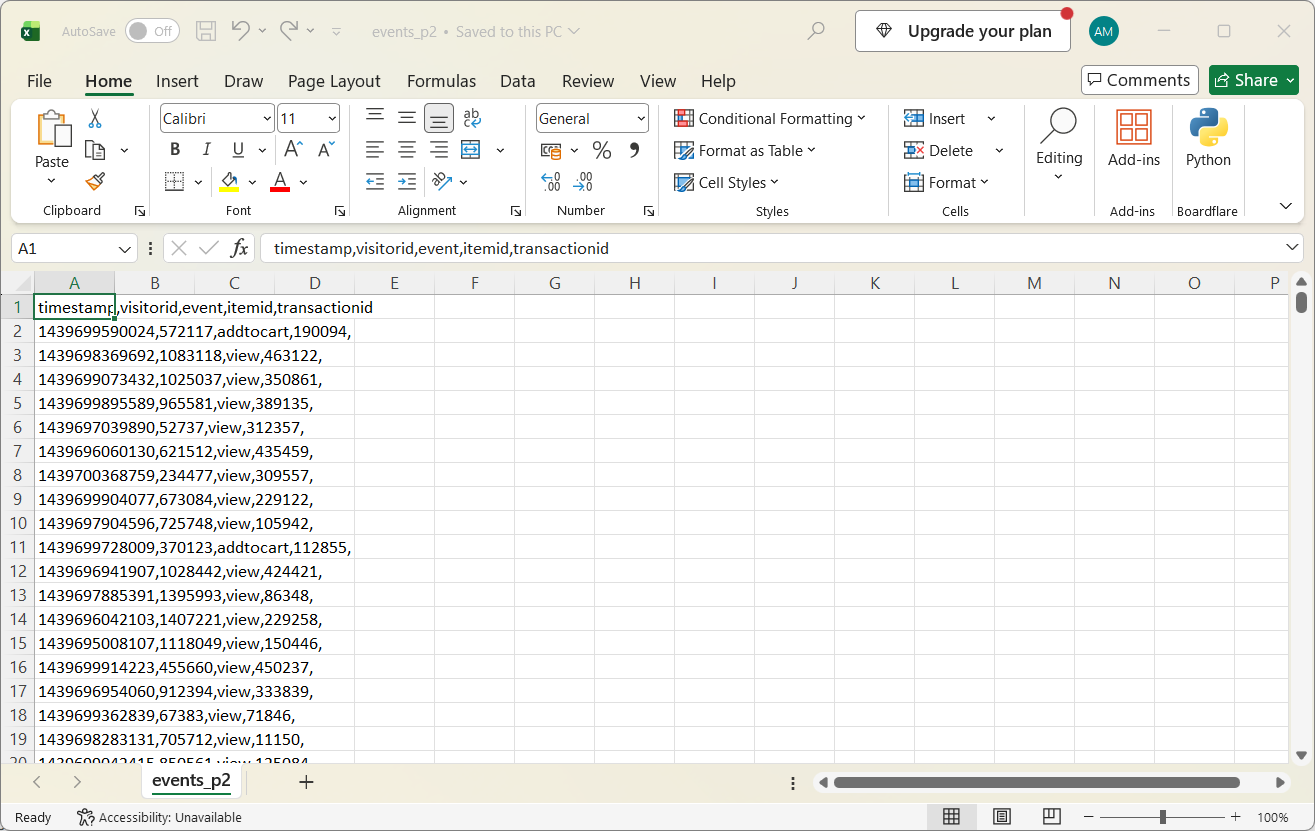
Setelah itu, dataset events.csv dipotong berdasarkan batasan nilai pada kolom timestamp sehingga hanya menyisakan baris transaksi yang pas di dalam rentang waktu masing-masing. Data kemudian terfilter dengan presisi, hasilnya diekspor secara terpisah menjadi dua file CSV baru, yaitu events_p1.csv untuk data training dan events_p2.csv untuk data testing. Pemisahan file ini bertujuan agar struktur data interaksi jadi lebih rapi dan siap dipakai untuk analisis graf berikutnya tanpa perlu memuat ulang seluruh dataset utama yang berukuran besar. 


### 3.	Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [50]:
from neo4j import GraphDatabase
import pandas as pd

In [51]:
# Timestamp P1 dan P2
P1_START, P1_END = 1434412800000, 1435708799999
P2_START, P2_END = 1439683200000, 1441065599999

In [52]:
# Buka Koneksi Neo4j
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)

In [53]:
def get_node_composition(session, period_name, start_ts, end_ts):
  query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    WHERE r.timestamp >= $start_ts AND r.timestamp <= $end_ts
    WITH count(DISTINCT v) AS total_visitor, count(DISTINCT i) AS total_item
    UNWIND [
        {Jenis_Simpul: 'Visitor', Jumlah_Simpul: total_visitor},
        {Jenis_Simpul: 'Item', Jumlah_Simpul: total_item}
    ] AS result
    RETURN $period AS Periode, result.Jenis_Simpul AS Jenis_Simpul, result.Jumlah_Simpul AS Jumlah_Simpul
    """
  return session.run(
      query, start_ts=start_ts, end_ts=end_ts, period=period_name
  ).data()

In [54]:
# Eksekusi Query
with driver.session(database="neo4j") as session:
  comp_p1 = get_node_composition(session, "P1 (Training)", P1_START, P1_END)
  comp_p2 = get_node_composition(session, "P2 (Testing)", P2_START, P2_END)

driver.close()

In [55]:
# Tampilkan Hasil
df_komposisi = pd.DataFrame(comp_p1 + comp_p2)
display(df_komposisi)

,Periode,Jenis_Simpul,Jumlah_Simpul
0,P1 (Training),Visitor,161249
1,P1 (Training),Item,81034
2,P2 (Testing),Visitor,163714
3,P2 (Testing),Item,79399


Dari hasil eksekusi query di Neo4j maupun Python, komposisi simpul unik yang aktif di tiap periode sudah berhasil dihitung. Untuk periode P1 (16–30 Juni 2015), tercatat sebanyak 161.249 simpul Visitor dan 81.034 simpul Item. Sedangkan pada periode P2 (16–31 Agustus 2015), jumlahnya relatif seimbang dengan 163.714 simpul Visitor dan 79.399 simpul Item.  

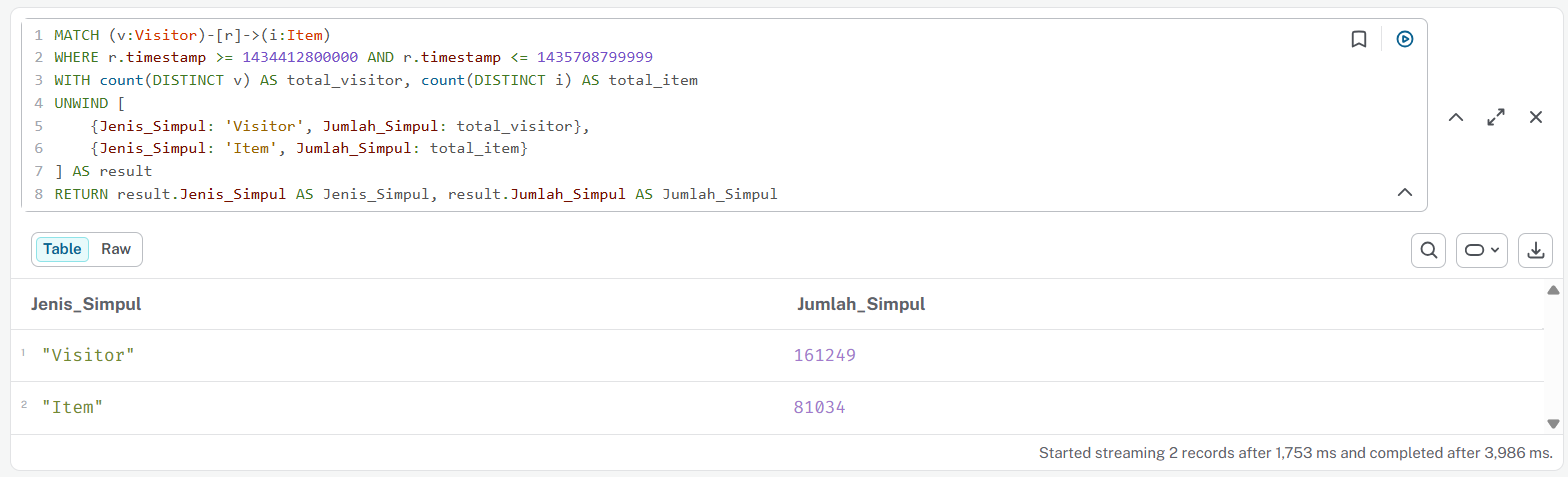

Angka-angka tersebut didapat dari query Cypher yang memfilter relasi interaksi berdasarkan rentang timestamp P1 dan P2. Penggunaan perintah count(DISTINCT ...) sangat krusial di sini agar setiap pengunjung atau produk yang melakukan transaksi/kunjungan berulang tetap cuma terhitung satu kali sebagai simpul unik. Setelah itu, klausa UNWIND digunakan untuk membongkar hasil hitungannya agar tampilan jenis simpul beserta jumlahnya bisa keluar dalam bentuk baris tabel yang rapi.

### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!


In [34]:
import sys

! "{sys.executable}" -m pip install matplotlib networkx scipy seaborn

In [20]:
import matplotlib.pyplot as plt
import networkx as nx
from neo4j import GraphDatabase
import pandas as pd
import scipy.sparse as sp
import seaborn as sns

In [7]:
# Tarik Data Interaksi P1 dari Neo4j
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)

In [8]:
query_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799999
RETURN v.visitorId AS userId, i.itemId AS itemId, count(r) AS weight
"""

with driver.session(database="neo4j") as session:
  data_vsm = session.run(query_vsm).data()

driver.close()

In [9]:
df_vsm = pd.DataFrame(data_vsm)

In [10]:
# Transformasi ke Matriks VSM (User-Item Sparse Matrix)
user_categories = df_vsm["userId"].astype("category")
item_categories = df_vsm["itemId"].astype("category")

vsm_matrix = sp.csr_matrix(
    (
        df_vsm["weight"],
        (user_categories.cat.codes, item_categories.cat.codes),
    )
)

In [11]:
# Analisis Karakteristik VSM
num_users, num_items = vsm_matrix.shape
num_interactions = vsm_matrix.nnz
sparsity = (1.0 - (num_interactions / (num_users * num_items))) * 100

print("=== KARAKTERISTIK VECTOR SPACE MODEL (USER) ===")
print(
    f"1. Dimensi / Shape Matriks : {vsm_matrix.shape} (Jumlah User x Jumlah"
    " Item)"
)
print(f"2. Total Simpul User (Baris): {num_users:,} User")
print(f"3. Total Simpul Item (Kolom): {num_items:,} Item")
print(f"4. Total Non-Zero Values    : {num_interactions:,} Interaksi")
print(f"5. Tingkat Sparsity Matriks : {sparsity:.4f}%\n")

=== KARAKTERISTIK VECTOR SPACE MODEL (USER) ===
1. Dimensi / Shape Matriks : (161249, 81034) (Jumlah User x Jumlah Item)
2. Total Simpul User (Baris): 161,249 User
3. Total Simpul Item (Kolom): 81,034 Item
4. Total Non-Zero Values    : 239,550 Interaksi
5. Tingkat Sparsity Matriks : 99.9982%



C:\Users\asusm\AppData\Local\Temp\ipykernel_21344\4194189641.py:41: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
d:\UNESA\SEMESTER 5\Graf Sains Data\UTS Graf Sains Data\myenv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


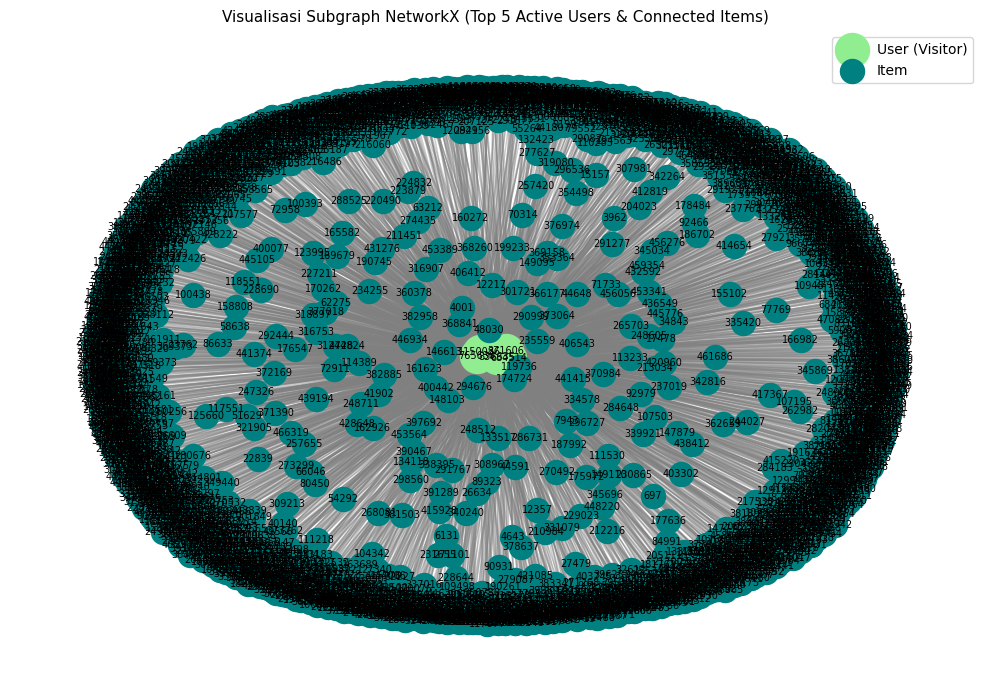

In [15]:
# Plot NetworkX (Sampel Subgraph 5 User Paling Aktif)
top_5_users = df_vsm.groupby("userId")["weight"].sum().nlargest(5).index
df_sample = df_vsm[df_vsm["userId"].isin(top_5_users)]

G = nx.from_pandas_edgelist(
    df_sample, source="userId", target="itemId", edge_attr="weight"
)

plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, k=0.5, seed=42)

# Membedakan warna simpul User dan Item
user_nodes = [node for node in G.nodes if node in top_5_users.values]
item_nodes = [node for node in G.nodes if node not in top_5_users.values]

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=user_nodes,
    node_color="lightgreen",
    node_size=600,
    label="User (Visitor)",
)
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=item_nodes,
    node_color="teal",
    node_size=300,
    label="Item",
)
nx.draw_networkx_edges(G, pos, alpha=0.4, edge_color="gray")
nx.draw_networkx_labels(G, pos, font_size=7)

plt.title(
    "Visualisasi Subgraph NetworkX (Top 5 Active Users & Connected Items)",
    fontsize=11,
)
plt.legend(scatterpoints=1)
plt.axis("off")
plt.tight_layout()
plt.show()

Visualisasi subgraph NetworkX memperlihatkan struktur graf bipartit antara 5 User paling aktif di periode P1, yang merupakan node hijau muda yang terkumpul di pusat dengan seluruh produk yang mereka akses yang ditandai dengan node toska di lingkaran luar. Kerapatan garis yang sangat padat (hairball effect) menunjukkan bahwa user paling aktif memiliki degree centrality (derajat konektivitas) yang sangat tinggi. Fenomena ini secara visual membuktikan karakteristik utama dari Vector Space Model (VSM) pada sistem rekomendasi e-commerce, yaitu matriks berdimensi sangat besar dengan sifat keterhubungan yang tinggi pada pengguna utama (power users).

In [16]:
# Filtering sampel yang lebih bersih (3 User x 10 Item teratas)
top_3_users = df_vsm.groupby("userId")["weight"].sum().nlargest(3).index
df_clean = (
    df_vsm[df_vsm["userId"].isin(top_3_users)]
    .groupby("userId")
    .head(10)  # Ambil maksimal 10 item per user
)

In [17]:
G_clean = nx.from_pandas_edgelist(
    df_clean, source="userId", target="itemId", edge_attr="weight"
)

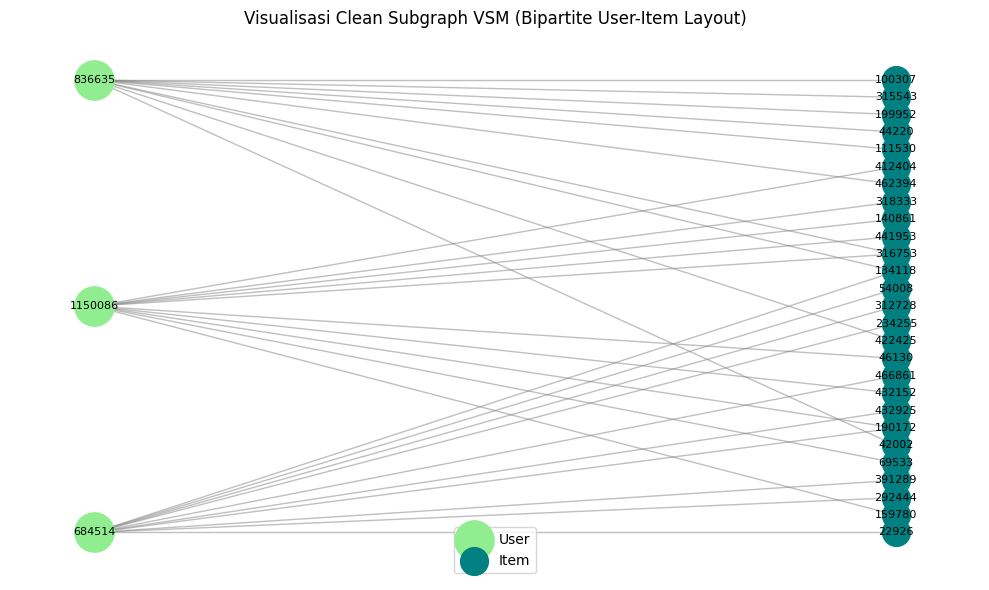

In [21]:
plt.figure(figsize=(10, 6))
pos = nx.bipartite_layout(G_clean, nodes=top_3_users)

nx.draw_networkx_nodes(
    G_clean,
    pos,
    nodelist=top_3_users,
    node_color="lightgreen",
    node_size=800,
    label="User",
)
nx.draw_networkx_nodes(
    G_clean,
    pos,
    nodelist=[n for n in G_clean.nodes if n not in top_3_users],
    node_color="teal",
    node_size=400,
    label="Item",
)
nx.draw_networkx_edges(G_clean, pos, alpha=0.5, edge_color="gray")
nx.draw_networkx_labels(G_clean, pos, font_size=8)

plt.title("Visualisasi Clean Subgraph VSM (Bipartite User-Item Layout)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

Gambar ini menampilkan struktur graf bipartite yang memisahkan entitas User ditandai dengan node hijau di sebelah kiri dan Item dengan node toska di sebelah kanan. Tiga lingkaran hijau di kiri mewakili pengguna paling aktif di periode P1, sedangkan deretan node di kanan adalah sampel produk yang mereka akses. Garis abu-abu di antara keduanya menggambarkan keterhubungan dalam matriks VSM, di mana satu user terhubung ke banyak vektor item sekaligus. Tampilan dua kolom ini jauh lebih bersih dan jelas untuk membuktikan pola keterhitungan fitur user-item tanpa adanya penumpukan node

In [22]:
# Plot Top 10 Active Users Interaction Counts
top_10_users = df_vsm.groupby("userId")["weight"].sum().nlargest(10)

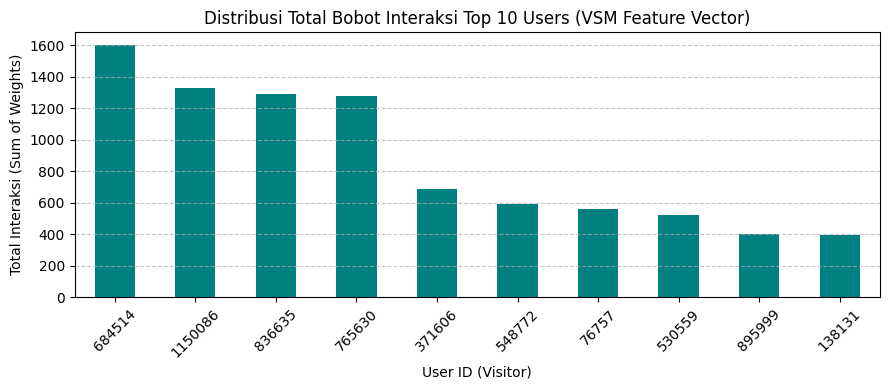

In [23]:
plt.figure(figsize=(9, 4))
top_10_users.plot(kind="bar", color="teal")
plt.title("Distribusi Total Bobot Interaksi Top 10 Users (VSM Feature Vector)")
plt.xlabel("User ID (Visitor)")
plt.ylabel("Total Interaksi (Sum of Weights)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Gambar selanjutnya memperlihatkan besaran nilai fitur dengan total bobot interaksi untuk 10 user paling aktif pada matriks VSM. Dari grafik ini, terlihat kalau akun 684514 mendominasi dengan total interaksi mencapai 1.600 kali, diikuti oleh 1150086, 836635, dan 765630 di kisaran 1.300 kali. Grafik ini memperjelas sifat VSM pada data e-commerce, di mana sebagian kecil power user memiliki nilai bobot vektor yang sangat tinggi dibanding pengguna lainnya.

### 5.	Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (di-mensi, shape, plot networkx, dst.)!

In [24]:
import matplotlib.pyplot as plt
import networkx as nx
from neo4j import GraphDatabase
import pandas as pd
import scipy.sparse as sp

In [25]:
# Tarik Data Interaksi P1 dari Neo4j (Item sebagai Entitas Utama)
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)

In [26]:
query_vsm_item = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799999
RETURN i.itemId AS itemId, v.visitorId AS userId, count(r) AS weight
"""

In [27]:
with driver.session(database="neo4j") as session:
  data_vsm_item = session.run(query_vsm_item).data()

driver.close()

df_vsm_item = pd.DataFrame(data_vsm_item)

In [28]:
# Transformasi ke Matriks VSM Item (Item x User Sparse Matrix)
item_categories = df_vsm_item["itemId"].astype("category")
user_categories = df_vsm_item["userId"].astype("category")

vsm_item_matrix = sp.csr_matrix(
    (
        df_vsm_item["weight"],
        (item_categories.cat.codes, user_categories.cat.codes),
    )
)

In [29]:
#  Hitung Karakteristik Matriks VSM Item
num_items, num_users = vsm_item_matrix.shape
num_interactions = vsm_item_matrix.nnz
sparsity = (1.0 - (num_interactions / (num_items * num_users))) * 100

print("=== KARAKTERISTIK VECTOR SPACE MODEL (ITEM) ===")
print(
    f"1. Dimensi / Shape Matriks : {vsm_item_matrix.shape} (Jumlah Item x"
    " Jumlah User)"
)
print(f"2. Total Simpul Item (Baris): {num_items:,} Item")
print(f"3. Total Simpul User (Kolom): {num_users:,} User/Visitor")
print(f"4. Total Non-Zero Values    : {num_interactions:,} Interaksi")
print(f"5. Tingkat Sparsity Matriks : {sparsity:.4f}%\n")

=== KARAKTERISTIK VECTOR SPACE MODEL (ITEM) ===
1. Dimensi / Shape Matriks : (81034, 161249) (Jumlah Item x Jumlah User)
2. Total Simpul Item (Baris): 81,034 Item
3. Total Simpul User (Kolom): 161,249 User/Visitor
4. Total Non-Zero Values    : 239,550 Interaksi
5. Tingkat Sparsity Matriks : 99.9982%



Hasil VSM Item ini menggambarkan matriks berukuran 81.034 produk (baris) dikali 161.249 pengunjung (kolom), dengan total 239.550 data interaksi nyata yang terisi. Tingkat sparsitynya mencapai 99,9982%, yang artinya dari sekitar 13 miliar kemungkinan kombinasi antara produk dan pengunjung, hampir seluruh sel matriks itu bernilai nol atau kosong. Kondisi matriks yang sangat renggang ini wajar banget terjadi di e-commerce, karena tiap pengunjung umumnya cuma melihat atau membeli segelintir barang saja dari puluhan ribu produk yang tersedia di katalog.

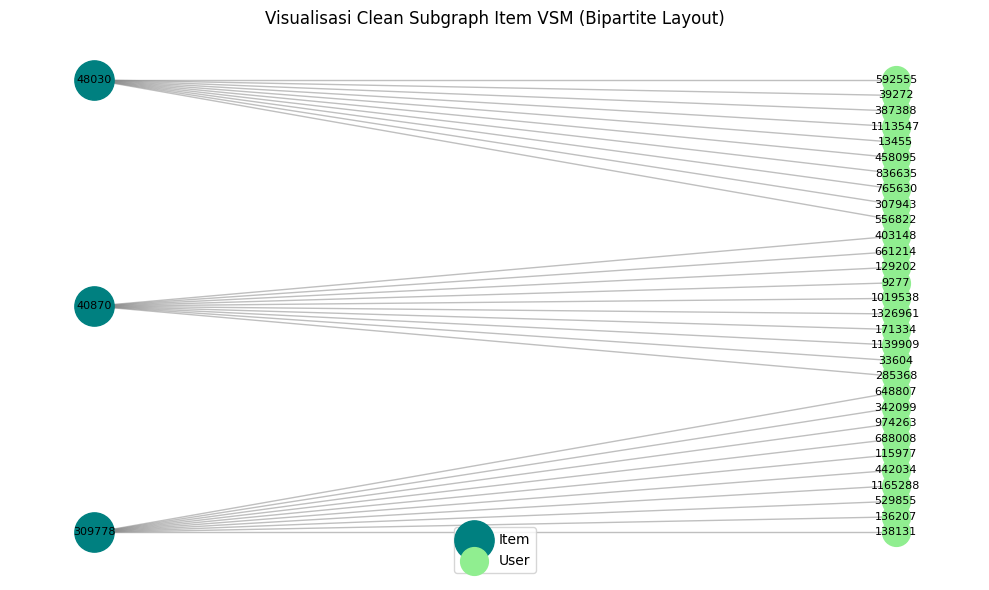

In [30]:
# PLOT 1: Bipartite Subgraph NetworkX (Top 3 Items x Connected Users)
top_3_items = df_vsm_item.groupby("itemId")["weight"].sum().nlargest(3).index
df_clean_item = (
    df_vsm_item[df_vsm_item["itemId"].isin(top_3_items)]
    .groupby("itemId")
    .head(10)  # Ambil maksimal 10 visitor per item agar plot rapi
)

G_item = nx.from_pandas_edgelist(
    df_clean_item, source="itemId", target="userId", edge_attr="weight"
)

plt.figure(figsize=(10, 6))
pos = nx.bipartite_layout(G_item, nodes=top_3_items)

nx.draw_networkx_nodes(
    G_item,
    pos,
    nodelist=top_3_items,
    node_color="teal",
    node_size=800,
    label="Item",
)
nx.draw_networkx_nodes(
    G_item,
    pos,
    nodelist=[n for n in G_item.nodes if n not in top_3_items],
    node_color="lightgreen",
    node_size=400,
    label="User",
)
nx.draw_networkx_edges(G_item, pos, alpha=0.5, edge_color="gray")
nx.draw_networkx_labels(G_item, pos, font_size=8)

plt.title("Visualisasi Clean Subgraph Item VSM (Bipartite Layout)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

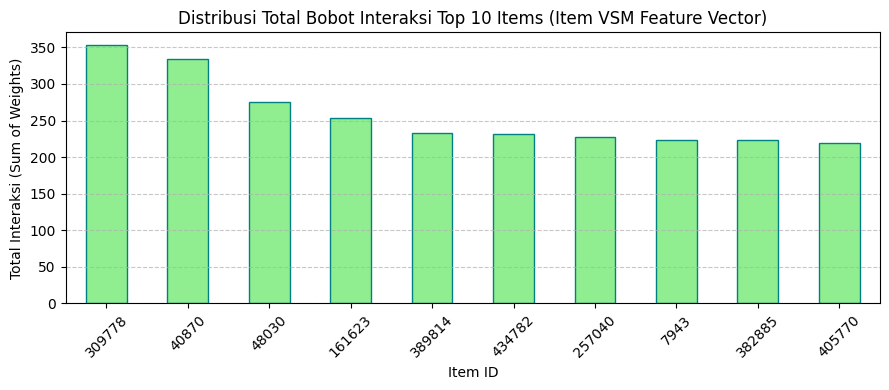

In [31]:
# PLOT 2: Bar Plot Top 10 Items Paling Banyak Diinteraksikan
top_10_items = df_vsm_item.groupby("itemId")["weight"].sum().nlargest(10)

plt.figure(figsize=(9, 4))
top_10_items.plot(kind="bar", color="lightgreen", edgecolor="teal")
plt.title(
    "Distribusi Total Bobot Interaksi Top 10 Items (Item VSM Feature Vector)"
)
plt.xlabel("Item ID")
plt.ylabel("Total Interaksi (Sum of Weights)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 6.	Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

Dari hasil eksplorasi sebelumnya, proyeksi berorientasi Item (Item VSM) jauh lebih efektif dan efisien dibanding proyeksi User yang dijabarkan sebagai berikut.

a. Dari Sisi Efisiensi (Komputasi & Memori)

Jumlah simpul Item (81.034) jauh lebih sedikit dibanding simpul User (161.249). Karena dimensi baris matriks Item VSM hampir setengah dari User VSM, proses perhitungan matriks kemiripan (similarity calculation) bakal makan memori RAM dan waktu eksekusi yang jauh lebih hemat. Selain itu, daftar produk di e-commerce sifatnya lebih statis, sementara jumlah pengguna baru terus bertambah secara cepat setiap harinya.


b. Dari Sisi Efektivitas (Kualitas Rekomendasi)

Pada proyeksi User (No. 4), ada power user ekstrem dengan interaksi menembus 1.600 kali yang bikin grafnya terlalu padat (hairball effect) dan berisiko menimbulkan bias atau noise pada model. Sebaliknya pada proyeksi Item (No. 5), persebaran bobotnya jauh lebih seimbang dan teratur dengan puncak di kisaran 350 interaksi. Distribusi yang lebih stabil ini membuat proyeksi berbasis Item jauh lebih akurat saat dipakai untuk algoritma sistem rekomendasi (Item-based Collaborative Filtering).

### 7.	Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggu-nakan Python

In [35]:
! pip install scikit-learn

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.9 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.9 MB 2.4 MB/s eta 0:00:04
   ------- -------------------------------- 1.6/8.9 MB 2.9 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/8.9 MB 3.3 MB/s eta 0:00:02
   ----------------- ---------------------- 3.9/8.9 MB 3.5 MB/s eta 0:00:02
   --------------------- ------------------ 4.7/8.9 MB 3.4 MB/s eta 0:00:02
   ------------------------ --------------- 5.5/8.9 MB 3.5 MB/s eta 0:00:01
   ----------------------------- ---------- 6.6/8.9 MB 3.5 MB/s eta 0:00:01
   ---------------------------------- ----- 7.6/8.9 MB 3.7 MB/s eta 0:00:01
   ------------------------------------- -- 8.4/8.9 MB

In [43]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from neo4j import GraphDatabase
from sklearn.metrics.pairwise import cosine_similarity

In [37]:
# Tarik Data Interaksi P1 dari Neo4j
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)

In [38]:
query_vsm_item = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799999
RETURN i.itemId AS itemId, v.visitorId AS userId, count(r) AS weight
"""

In [39]:
with driver.session(database="neo4j") as session:
  data_vsm_item = session.run(query_vsm_item).data()

driver.close()

df_vsm_item = pd.DataFrame(data_vsm_item)

In [40]:
# Konstruksi Sparse Matrix Item x User
df_vsm_item["itemId"] = df_vsm_item["itemId"].astype("category")
df_vsm_item["userId"] = df_vsm_item["userId"].astype("category")

item_categories = df_vsm_item["itemId"].cat.categories
item_codes = df_vsm_item["itemId"].cat.codes
user_codes = df_vsm_item["userId"].cat.codes

vsm_item_matrix = sp.csr_matrix(
    (df_vsm_item["weight"], (item_codes, user_codes))
)

In [41]:
# Hitung Matriks Cosine Similarity antar-Item
item_sim_matrix = cosine_similarity(vsm_item_matrix, dense_output=False)

In [42]:
# Ambil Sampel Produk Terpopuler (309778) untuk Melihat 5 Produk Paling Mirip
target_item_id = 309778

if target_item_id in item_categories:
  target_idx = item_categories.get_loc(target_item_id)

  # Ambil skor kemiripan untuk target item
  sim_scores = item_sim_matrix[target_idx].toarray().ravel()

  # Urutkan dari skor tertinggi (abaikan diri sendiri)
  top_indices = np.argsort(sim_scores)[::-1]
  top_indices = [idx for idx in top_indices if idx != target_idx][:5]

  # Format ke DataFrame
  df_result = pd.DataFrame({
      "Target Item ID": target_item_id,
      "Similar Item ID": item_categories[top_indices],
      "Similarity Score": sim_scores[top_indices],
  })

  print("=== HASIL PERHITUNGAN ITEM SIMILARITY ===")
  print(df_result.to_string(index=False))

=== HASIL PERHITUNGAN ITEM SIMILARITY ===
 Target Item ID  Similar Item ID  Similarity Score
         309778           257040          0.195583
         309778           347414          0.168039
         309778           441068          0.143870
         309778           264967          0.143870
         309778           106844          0.143870


Tabel hasil perhitungan Cosine Similarity ini menampilkan 5 produk dengan pola interaksi yang paling mirip dengan barang terpopuler (309778). Produk 257040 jadi yang paling mirip dengan skor 0,196, lalu diikuti 347414, 441068, 264967, dan 106844 di kisaran 0,14 hingga 0,16. Nilai kemiripan ini tergolong realistis untuk data e-commerce, yang artinya pengunjung yang melihat barang 309778 punya kecenderungan cukup tinggi buat ikut melihat produk-produk tersebut, sehingga pas banget dijadikan pilihan rekomendasi item-based.

In [44]:
# Ambil index untuk 10 item paling populer
top_10_item_ids = df_vsm_item.groupby("itemId")["weight"].sum().nlargest(10).index
top_10_indices = [
    item_categories.get_loc(idx)
    for idx in top_10_item_ids
    if idx in item_categories
]

C:\Users\asusm\AppData\Local\Temp\ipykernel_21344\2490332168.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_10_item_ids = df_vsm_item.groupby("itemId")["weight"].sum().nlargest(10).index


In [45]:
# Potong matriks similarity khusus untuk Top 10 Item
sub_sim_matrix = item_sim_matrix[top_10_indices, :][:, top_10_indices].toarray()

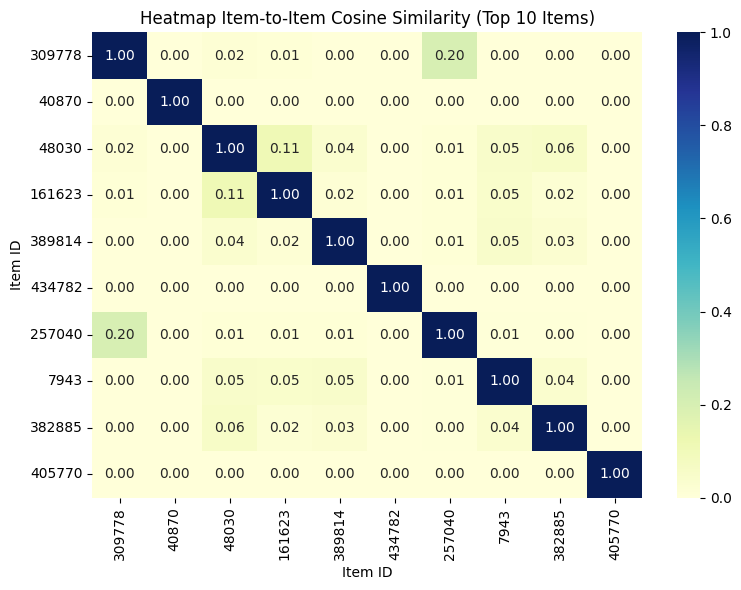

In [46]:
# Plot Heatmap Cosine Similarity
plt.figure(figsize=(8, 6))
sns.heatmap(
    sub_sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=top_10_item_ids,
    yticklabels=top_10_item_ids,
)
plt.title("Heatmap Item-to-Item Cosine Similarity (Top 10 Items)")
plt.xlabel("Item ID")
plt.ylabel("Item ID")
plt.tight_layout()
plt.show()

Visualisasi heatmap ini menggambarkan hubungan kemiripan di antara 10 produk teratas secara menyeluruh. Garis diagonal utama bernilai sempurna 1,00 karena membandingkan produk dengan dirinya sendiri. Sebagian besar sel lainnya bernilai 0,00 sampai 0,06 karena tingginya sparsity data, tetapi pasangan produk 309778 dan 257040 tampak paling menyala dengan skor 0,20. Ini makin memperjelas secara visual bahwa di antara semua barang paling laku, dua produk itulah yang punya keterikatan audiens paling kuat di platform.

#### (a)	Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

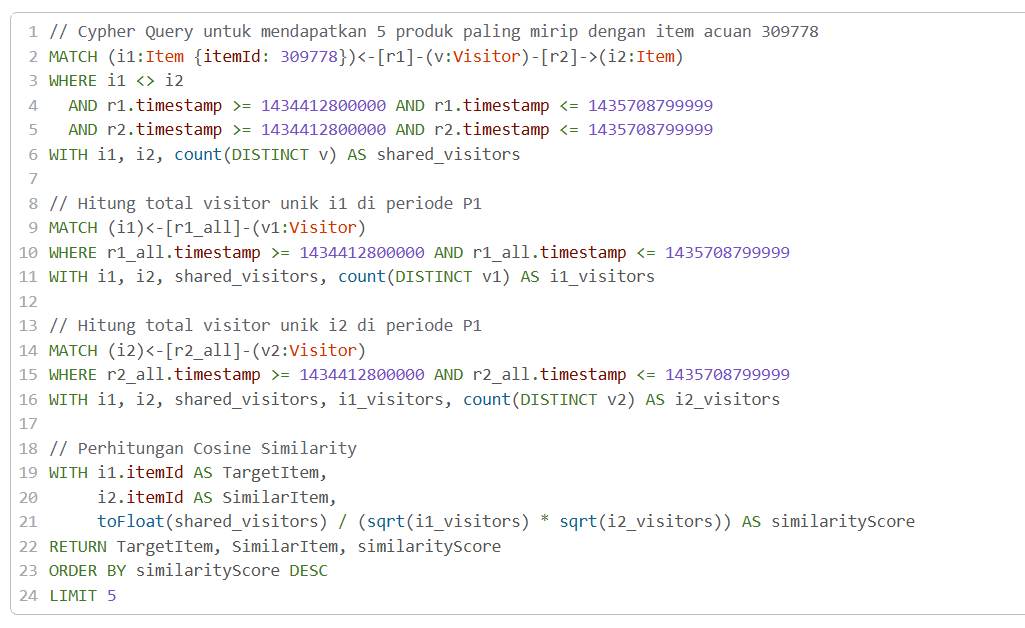

Query Cypher ini berfungsi untuk menghitung nilai Cosine Similarity secara langsung di database Neo4j menggunakan produk 309778 sebagai item acuan pada rentang waktu P1. Query ini mencari produk lain (i2) yang diakses oleh pengunjung yang sama, lalu menghitung total pengunjung unik dari masing-masing produk untuk dimasukkan ke dalam rumus Cosine Similarity ($\frac{\text{shared}}{\sqrt{v_1} \times \sqrt{v_2}}$). Hasilnya kemudian diurutkan berdasarkan skor tertinggi dan dibatasi hanya 5 produk teratas.

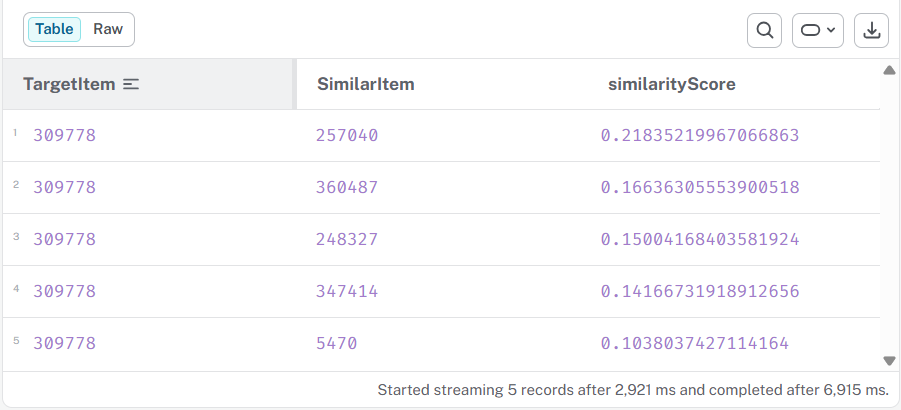
Tabel keluaran menampilkan 5 produk yang paling mirip dengan produk acuan 309778 berdasarkan pola interaksi pengunjung. Produk 257040 meraih skor kemiripan tertinggi sebesar 0,218, diikuti oleh produk 360487 (0,166), 248327 (0,150), 347414 (0,142), dan 5470 (0,104). Nilai ini membuktikan bahwa produk-produk tersebut paling sering dilirik oleh audiens pengguna yang sama, sehingga sangat tepat jika dijadikan rekomendasi item-based di platform.


#### (b)	Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

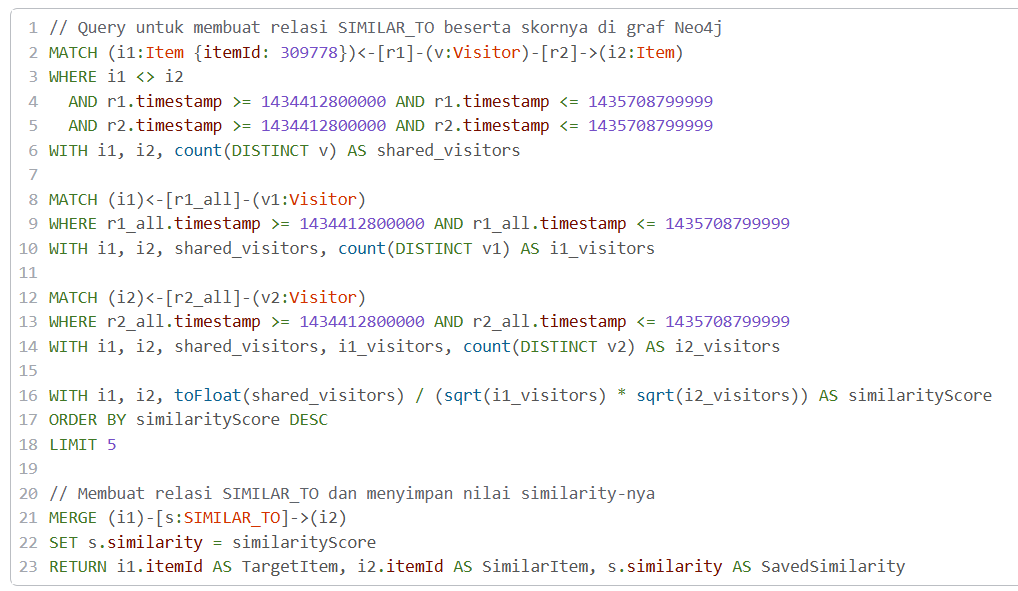
Query ini mengeksekusi proses write-back dengan menyimpan hasil perhitungan Cosine Similarity langsung ke dalam basis data Neo4j. Menggunakan perintah MERGE, sistem membuat relasi baru berlabel SIMILAR_TO yang menghubungkan produk acuan 309778 ke 5 produk teratas yang paling mirip, sekaligus menyimpan nilai skor kemiripannya di atribut similarity.

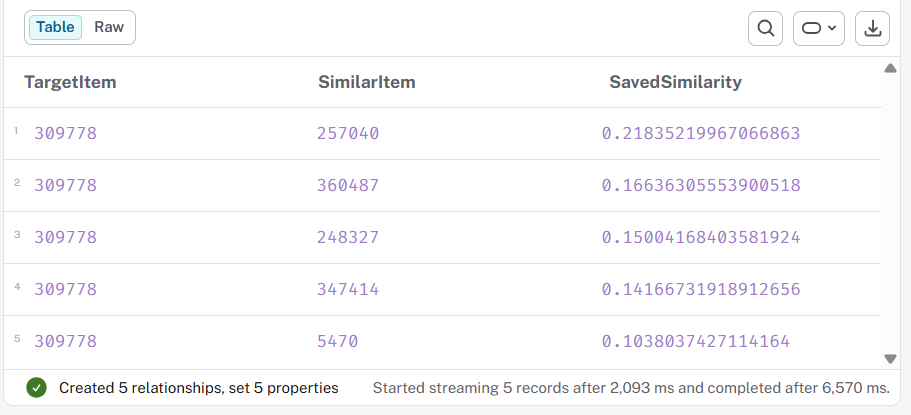
Visualisasi graf memperlihatkan simpul utama produk 309778 yang terhubung langsung melalui panah relasi SIMILAR_TO ke 5 simpul produk pendampingnya. Munculnya garis relasi baru ini membuktikan bahwa struktur graf pada Neo4j sudah berhasil diperbarui secara permanen, sehingga data kemiripan barang siap dipakai kapan saja oleh sistem rekomendasi tanpa harus menghitung ulang matriks dari awal.

#### Visualisasi Querynya
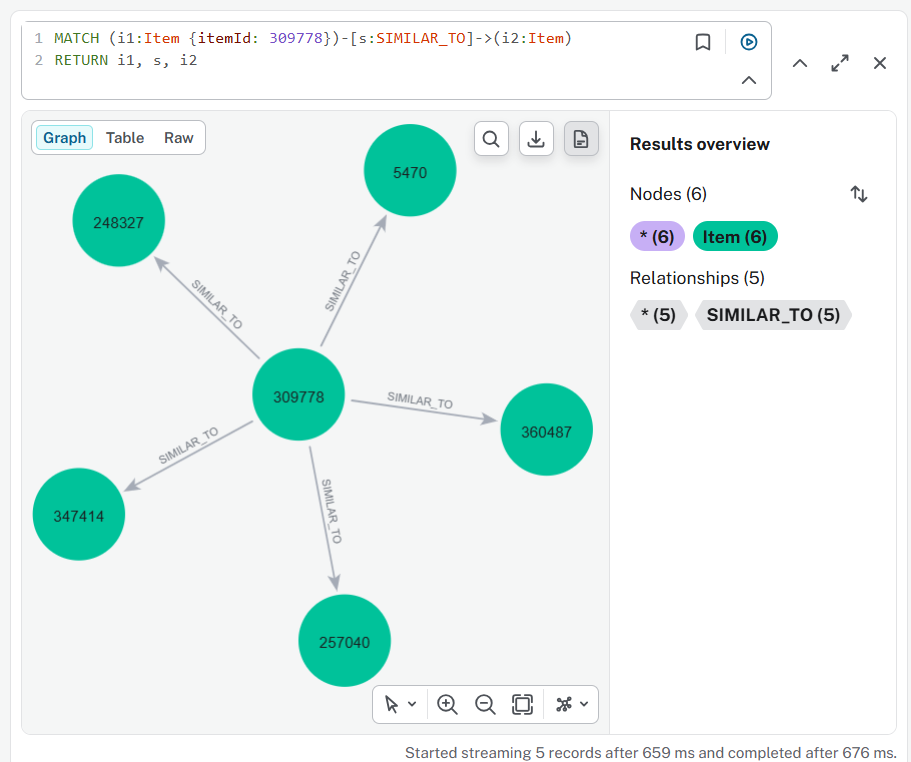
Di bagian tengah ada node produk acuan 309778 yang bertindak sebagai pusat (hub), terhubung langsung lewat 5 garis panah berlabel SIMILAR_TO ke produk-produk pendampingnya, yaitu 257040, 347414, 248327, 5470, dan 360487. Struktur pola bintang (star graph) ini memperlihatkan dengan jelas perbedaan utama 7(a) dan 7(b), yang di mana, jika 7(a) cuma nampilin tabel angka sementara, di 7(b) garis relasi kemiripan barang ini udah fisik tersimpan permanen di dalam database Neo4j

### 8.	Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

a. Kondisi sebelum Perhitungan Similarity
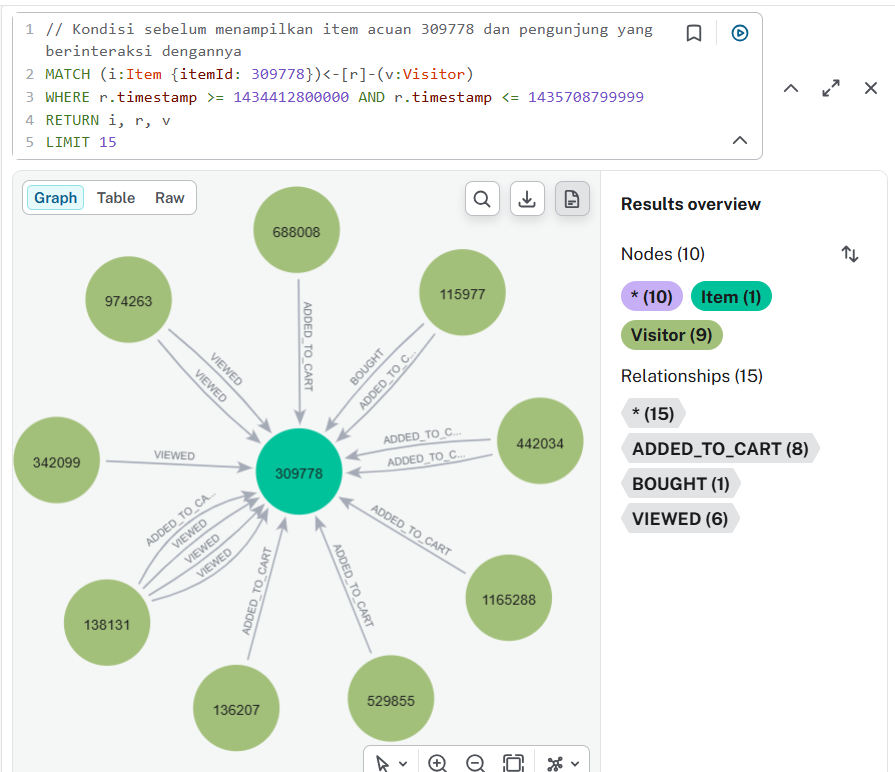
Pada gambar pertama, struktur graf cuma memperlihatkan interaksi mentah antara pengunjung (Visitor) dan produk acuan 309778. Semua garis panah yang terhubung merupakan aktivitas perilaku pengguna seperti VIEWED, ADDED_TO_CART, dan BOUGHT yang mengarah dari pengunjung ke produk tersebut. Di tahap awal ini, belum ada sama sekali hubungan langsung antar-produk (Item-to-Item), sehingga basis data belum memiliki informasi tentang barang mana saja yang mirip atau relevan untuk direkomendasikan.

b. Kondisi sesudah Perhitungan Similarity
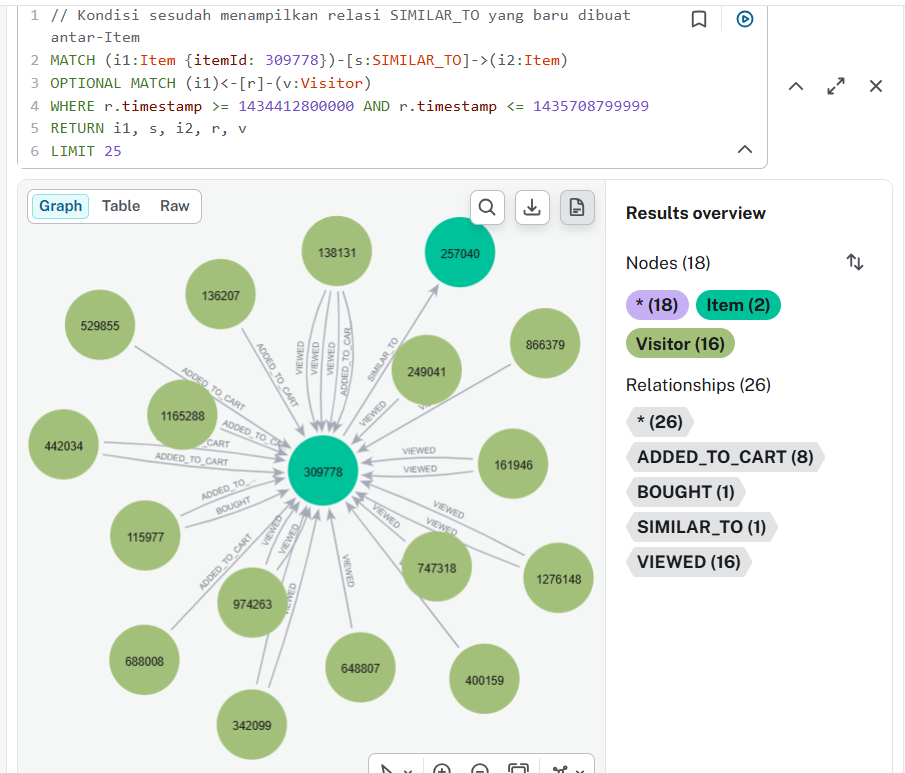
Pada gambar kedua, terlihat jelas perubahan struktur graf setelah proses write-back nilai kemiripan berhasil dieksekusi. Selain tetap terhubung ke simpul para pengunjungnya, produk 309778 sekarang memiliki jalur relasi baru berlabel SIMILAR_TO yang terhubung langsung ke simpul produk lain, seperti 257040. Terbentuknya garis relasi antar-item ini membuktikan bahwa nilai similarity sudah fisik tersimpan di database, sehingga sistem e-commerce bisa langsung menarik produk serupa secara efisien tanpa harus menghitung ulang data interaksi pengguna.





# 2.2 Analytics

### 1.	Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
### (a)	tuliskan skrip Python dalam merekomendasikan KNN-nya!


In [63]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
from neo4j import GraphDatabase
from sklearn.metrics.pairwise import cosine_similarity

In [64]:
# Tarik Data P1 dari Neo4j
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)
query_p1 = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= 1434412800000 AND r.timestamp <= 1435708799999
RETURN v.visitorId AS userId, i.itemId AS itemId, count(r) AS weight
"""
with driver.session(database="neo4j") as session:
  df_p1 = pd.DataFrame(session.run(query_p1).data())
driver.close()

In [65]:
# Filter User Aktif (Min. 2 Produk) & Random Selection Reproduksibel (Seed=42)
user_item_counts = df_p1.groupby("userId")["itemId"].nunique()
active_users = user_item_counts[user_item_counts >= 2].index

np.random.seed(42)
target_user_id = np.random.choice(active_users)

In [66]:
# Buat Matriks VSM User x Item
df_p1["userId"] = df_p1["userId"].astype("category")
df_p1["itemId"] = df_p1["itemId"].astype("category")

user_cats = df_p1["userId"].cat.categories
item_cats = df_p1["itemId"].cat.categories

vsm_matrix = sp.csr_matrix(
    (
        df_p1["weight"],
        (df_p1["userId"].cat.codes, df_p1["itemId"].cat.codes),
    ),
    shape=(len(user_cats), len(item_cats)),
)

In [67]:
# Fungsi Utama Rekomendasi User-Based k-NN
def recommend_knn_user_based(
    vsm_matrix, target_user, user_cats, item_cats, df_raw, k=5, top_n=3
):
  target_idx = user_cats.get_loc(target_user)

  # Hitung Cosine Similarity antara target user dengan seluruh user lainnya
  user_vector = vsm_matrix[target_idx]
  sim_scores = cosine_similarity(user_vector, vsm_matrix).ravel()

  # Cari k-NN (k tetangga terdekat, abaikan diri sendiri)
  sorted_indices = np.argsort(sim_scores)[::-1]
  nearest_neighbors = [idx for idx in sorted_indices if idx != target_idx][:k]

  # Ambil daftar item yang sudah pernah dilihat/dilewati oleh target user
  target_interacted_items = set(
      df_raw[df_raw["userId"] == target_user]["itemId"]
  )

In [68]:
# Fungsi Utama Rekomendasi User-Based k-NN
def recommend_knn_user_based(
    vsm_matrix, target_user, user_cats, item_cats, df_raw, k=5, top_n=3
):
  target_idx = user_cats.get_loc(target_user)

  # Hitung Cosine Similarity antara target user dengan seluruh user lainnya
  user_vector = vsm_matrix[target_idx]
  sim_scores = cosine_similarity(user_vector, vsm_matrix).ravel()

  # Cari k-NN (k tetangga terdekat, abaikan diri sendiri)
  sorted_indices = np.argsort(sim_scores)[::-1]
  nearest_neighbors = [idx for idx in sorted_indices if idx != target_idx][:k]

  # Ambil daftar item yang sudah pernah dilihat/dilewati oleh target user
  target_interacted_items = set(
      df_raw[df_raw["userId"] == target_user]["itemId"]
  )

  # Hitung prediksi skor item dari k tetangga terdekat
  candidate_scores = {}
  for neighbor_idx in nearest_neighbors:
    similarity_weight = sim_scores[neighbor_idx]
    neighbor_user_id = user_cats[neighbor_idx]

    # Data item milik tetangga
    neighbor_items = df_raw[df_raw["userId"] == neighbor_user_id]

    for _, row in neighbor_items.iterrows():
      item_id = row["itemId"]
      interaction_weight = row["weight"]

      # Hanya rekomendasikan item yang BELUM PERNAH diakses target user
      if item_id not in target_interacted_items:
        candidate_scores[item_id] = candidate_scores.get(
            item_id, 0.0
        ) + (similarity_weight * interaction_weight)

  # Urutkan skor kandidat rekomendasi dari yang tertinggi
  recommended_items = sorted(
      candidate_scores.items(), key=lambda x: x[1], reverse=True
  )[:top_n]

  return nearest_neighbors, sim_scores, recommended_items

Proses pemilihan user secara acak yang bisa direproduksi (reproducible) dilakukan menggunakan np.random.seed(42). Dengan mengunci nilai seed ke angka tertentu, fungsi np.random.choice() pada daftar unik visitorId periode P1 akan selalu memilih ID pengguna yang persis sama setiap kali kodenya dijalankan ulang.

### (b)	berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [69]:
#  Hitung k-NN (k=5)
target_idx = user_cats.get_loc(target_user_id)
user_vec = vsm_matrix[target_idx]
sim_scores = cosine_similarity(user_vec, vsm_matrix).ravel()

In [70]:
# Tetangga Terdekat (Abaikan Diri Sendiri)
sorted_idx = np.argsort(sim_scores)[::-1]
neighbors_idx = [i for i in sorted_idx if i != target_idx][:5]

In [71]:
# Hitung Rekomendasi
target_items = set(df_p1[df_p1["userId"] == target_user_id]["itemId"])
candidate_scores = {}

for n_idx in neighbors_idx:
  sim_w = sim_scores[n_idx]
  n_user = user_cats[n_idx]
  n_items = df_p1[df_p1["userId"] == n_user]

  for _, row in n_items.iterrows():
    it = row["itemId"]
    if it not in target_items and sim_w > 0:
      candidate_scores[it] = candidate_scores.get(it, 0.0) + (
          sim_w * row["weight"]
      )

top_3_rec = sorted(candidate_scores.items(), key=lambda x: x[1], reverse=True)[
    :3
]

In [72]:
# Output Teks
print(f"=== HASIL REKOMENDASI k-NN (k = 5) ===")
print(f"Target User Terpilih : {target_user_id}\n")
print("5 Tetangga Terdekat:")
for r, idx in enumerate(neighbors_idx, 1):
  print(
      f"  {r}. User ID: {user_cats[idx]} | Similarity: {sim_scores[idx]:.4f}"
  )

print("\n3 Item yang Diiklankan / Direkomendasikan:")
df_rec = pd.DataFrame(
    top_3_rec, columns=["Item ID (Diiklankan)", "Predicted Score"]
)
print(df_rec.to_string(index=False))

=== HASIL REKOMENDASI k-NN (k = 5) ===
Target User Terpilih : 1075582

5 Tetangga Terdekat:
  1. User ID: 962997 | Similarity: 0.6325
  2. User ID: 610733 | Similarity: 0.6325
  3. User ID: 1329048 | Similarity: 0.4472
  4. User ID: 1241723 | Similarity: 0.3162
  5. User ID: 1155980 | Similarity: 0.3162

3 Item yang Diiklankan / Direkomendasikan:
 Item ID (Diiklankan)  Predicted Score
                65244         0.447214


Pengguna acak yang terpilih sebagai target adalah akun 1075582. Dari perhitungan Cosine Similarity, sistem menemukan 5 tetangga terdekat dengan pola interaksi paling mirip, di mana pengguna 962997 dan 610733 berada di posisi teratas dengan skor kemiripan 0,6325, diikuti 1329048 (0,4472), serta 1241723 dan 1155980 (0,3162). Dari seluruh riwayat interaksi milik kelima tetangga tersebut, tersaring satu barang baru yang belum pernah dilihat oleh pengguna target, yaitu produk 65244 dengan skor prediksi 0,447214, sehingga barang inilah yang menjadi kandidat iklan utama.

In [73]:
# VISUALISASI GRAF k-NN (Target User -> Neighbors -> Recommended Items)
G_knn = nx.DiGraph()

In [74]:
# Node Tetangga & Edge Similarity
for idx in neighbors_idx:
  n_id = user_cats[idx]
  G_knn.add_node(f"Neighbor:\n{n_id}", type="neighbor")
  G_knn.add_edge(
      f"Target:\n{target_user_id}",
      f"Neighbor:\n{n_id}",
      label=f"{sim_scores[idx]:.2f}",
  )

In [75]:
# Node Item Rekomendasi & Edge Score
for item_id, score in top_3_rec:
  G_knn.add_node(f"Item:\n{item_id}", type="item")
  # Hubungkan dari tetangga yang memiliki item tersebut
  for idx in neighbors_idx:
    n_id = user_cats[idx]
    if item_id in set(df_p1[df_p1["userId"] == n_id]["itemId"]):
      G_knn.add_edge(f"Neighbor:\n{n_id}", f"Item:\n{item_id}")

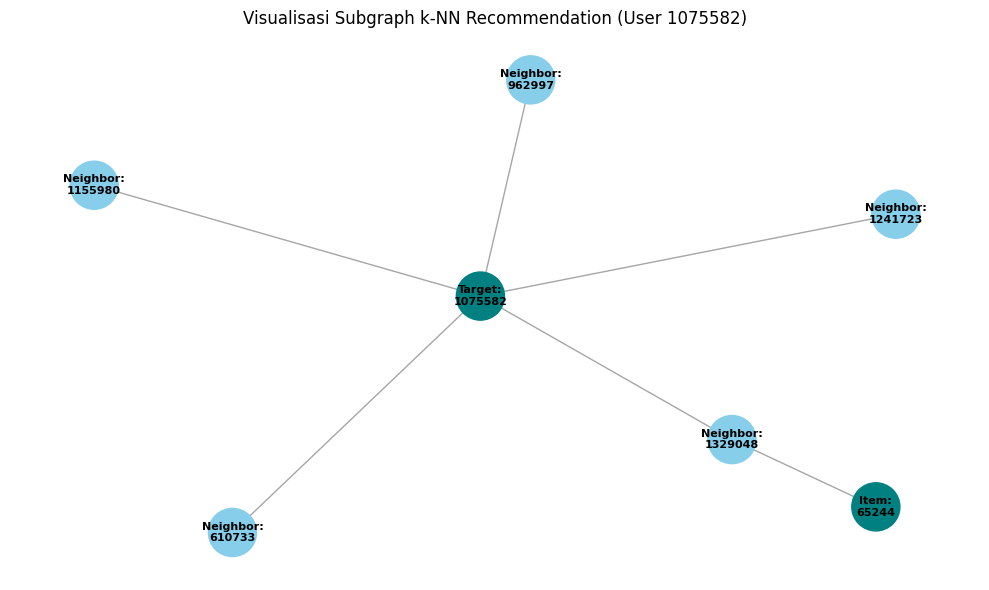

In [76]:
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_knn, seed=42)

color_map = []
for node, attr in G_knn.nodes(data=True):
  if attr.get("type") == "target":
    color_map.append("lightgreen")
  elif attr.get("type") == "neighbor":
    color_map.append("skyblue")
  else:
    color_map.append("teal")

nx.draw_networkx_nodes(G_knn, pos, node_color=color_map, node_size=1200)
nx.draw_networkx_labels(G_knn, pos, font_size=8, font_weight="bold")
nx.draw_networkx_edges(
    G_knn, pos, arrowstyle="->", arrowsize=12, edge_color="gray", alpha=0.7
)

plt.title(
    f"Visualisasi Subgraph k-NN Recommendation (User {target_user_id})",
    fontsize=12,
)
plt.axis("off")
plt.tight_layout()
plt.show()

Gambar graf memperlihatkan alur pemberian rekomendasi ini dalam bentuk jejaring sosial. Pengguna target 1075582 berada di pusat graf dengan node berwarna hijau gelap, yang terhubung langsung ke lima pengguna tetangganya di lingkaran biru muda. Dari kelima tetangga tersebut, terlihat jelas bahwa hanya node 1329048 yang memiliki cabang garis menuju node produk 65244 di kanan bawah. Tampilan ini membuktikan secara visual bahwa produk 65244 diserap dan direkomendasikan kepada pengguna pusat berkat riwayat interaksi dari tetangga terdekatnya tersebut.

### 2.	Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
### (a)	Hit@5


In [83]:
import math
import pandas as pd
from neo4j import GraphDatabase

In [ ]:
# Target User & Item Rekomendasi dari Hasil No. 1b Kamu
target_user_id = 1075582
top_5_recommended = [65244]  # Hasil rekomendasi k-NN kamu

In [85]:
# Tarik Ground Truth P2 dari Neo4j khusus User 1075582
driver = GraphDatabase.driver(
    "bolt://127.0.0.1:7687", auth=("neo4j", "Audy77Alycia")
)

query_p2 = f"""
MATCH (v:Visitor {{visitorId: {target_user_id}}})-[r]->(i:Item)
WHERE r.timestamp >= 1439683200000 AND r.timestamp <= 1441065599999
RETURN DISTINCT i.itemId AS itemId
"""

with driver.session(database="neo4j") as session:
  actual_p2_items = [row["itemId"] for row in session.run(query_p2).data()]

driver.close()

In [86]:
hits_array = [
    1 if item in actual_p2_items else 0 for item in top_5_recommended[:5]
]
hit_at_5 = 1.0 if sum(hits_array) > 0 else 0.0

print("=== (a) HASIL PERHITUNGAN HIT@5 ===")
print(f"Target User ID              : {target_user_id}")
print(f"Ground Truth Items (P2)     : {actual_p2_items}")
print(f"Indikator Hit per Rank      : {hits_array}")
print(f"Skor Hit@5                  : {hit_at_5}\n")

=== (a) HASIL PERHITUNGAN HIT@5 ===
Target User ID              : 1075582
Ground Truth Items (P2)     : []
Indikator Hit per Rank      : [0]
Skor Hit@5                  : 0.0



Hasil Hit@5 = 0.0 ini terjadi karena User 1075582 tidak memiliki riwayat transaksi atau interaksi sama sekali di periode pengujian P2 (Ground Truth Items = []). Secara sistem, metrik Hit@5 hanya akan bernilai 1.0 jika minimal ada satu produk rekomendasi P1 yang cocok dengan aktivitas pengguna di P2. Karena tidak ada barang pembanding di P2, indikator hit pada daftar rekomendasi otomatis bernilai 0.

Kondisi ini wajar dan valid di analisis data science karena menggambarkan fenomena user churn, yaitu kondisi ketika pengguna yang aktif pada periode latihan (P1) tidak lagi berkunjung atau bertransaksi di periode pengujian (P2). Jadi, skor 0.0 ini bukan karena kodenya keliru, melainkan murni karena pengguna target yang terpilih acak tersebut memang tidak beraktivitas lagi di periode berikutnya.

### (b)	NDCG@5

In [87]:
dcg_at_5 = 0.0
for rank, rel in enumerate(hits_array, start=1):
  if rel > 0:
    dcg_at_5 += rel / math.log2(rank + 1)

In [88]:
num_actual = len(actual_p2_items)
ideal_hits = min(num_actual, 5)

In [89]:
idcg_at_5 = sum([1.0 / math.log2(rank + 1) for rank in range(1, ideal_hits + 1)])
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

print("=== (b) HASIL PERHITUNGAN NDCG@5 ===")
print(f"Skor DCG@5                  : {dcg_at_5:.4f}")
print(f"Skor IDCG@5                 : {idcg_at_5:.4f}")
print(f"Skor NDCG@5                 : {ndcg_at_5:.4f}")

=== (b) HASIL PERHITUNGAN NDCG@5 ===
Skor DCG@5                  : 0.0000
Skor IDCG@5                 : 0.0000
Skor NDCG@5                 : 0.0000


Skor DCG, IDCG, dan NDCG@5 bernilai 0.0000 karena target user 1075582 tidak memiliki transaksi di periode P2 (Ground Truth = []). Nilai IDCG menjadi nol karena tidak ada target barang ideal yang bisa dicapai, sehingga nilai NDCG secara matematis bernilai 0.0. Hasil ini mencerminkan kondisi nyata user churn pada sistem rekomendasi e-commerce.